# CE23: LATTE across the selected IN2023_V06 ADCP survey

Fit **all usable ADCP observations from 17 October 2023 10:27:31 through 21 October 2023 22:27:30.333 UTC**, without a geographic filter. CSV rows outside this inclusive window are excluded. CE23 is cyclonic; relative vorticity is expected negative.

The selected SOLO crossing's shallowest accepted inner centre supplies the initial geographic origin, exactly as in the Murphy LATTE workflow. A rejected Gaussian SOLO radius does not disqualify an accepted inner centre. LATTE follows accepted centres and ellipses through the actual measured depths; failed levels remain gaps. Sampling spans several days, so temporal evolution and spatial structure can be aliased. The deepest observed bin does not establish the eddy bottom.

Run `CE23_solo.ipynb` and its export first. These new notebooks have no executed scientific outputs. Fit settings copied from Murphy are editable starting values, not CE23-validated choices.


In [30]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

## Controls and SOLO starting centre

Edit `CE23_latte.json` for the inclusive UTC window, SOLO seed ID and complete LATTE fit settings. Crossing definitions live in `transects.json`. Rerun SOLO exports before LATTE after modifying crossing windows, origins or SOLO fits.

Choose `adcp_instrument`: `"OS150"` or `"WH75"` in this notebook’s JSON. This selects one source before all sampling and fits. After changing instruments, rerun SOLO and its export before rerunning LATTE.


In [31]:
EDDY = "CE23"
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2023_V06_adcp_trawler"
CONFIG_PATH = STUDY_DIR / "CE23_latte.json"
CONFIG = json.loads(CONFIG_PATH.read_text())
ADCP_INSTRUMENT = CONFIG["adcp_instrument"]
if ADCP_INSTRUMENT not in ("OS150", "WH75"):
    raise ValueError("adcp_instrument must be OS150 or WH75")
TRANSECTS_PATH = STUDY_DIR / CONFIG["transects_config"]
BACKEND_PATH = Path(CONFIG["backend_path"])
DATA_PATH, transects, _ = esp.load_study(TRANSECTS_PATH, EDDY, load_adcp=False)
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "ce23_solo_depth_fits.csv"
SOLO_TRANSECT = CONFIG["solo_transect"]
WINDOW_START = pd.Timestamp(CONFIG["time_window_utc"]["start"])
WINDOW_END = pd.Timestamp(CONFIG["time_window_utc"]["end"])
if any(t.tzinfo is None or t.utcoffset().total_seconds() != 0 for t in (WINDOW_START, WINDOW_END)) or WINDOW_END <= WINDOW_START:
    raise ValueError("time_window_utc must contain increasing UTC timestamps")
MAP_DEPTHS = tuple(CONFIG["map_depths"])
MIN_ATTENDANCE = CONFIG["min_attendance"]
FIT = CONFIG["fit"]
HALF_WIDTH_KM = CONFIG["half_width_km"]
VELOCITY_LIMIT = CONFIG["velocity_limit"]

if SOLO_TRANSECT not in transects.index:
    raise ValueError(f"SOLO_TRANSECT must be one of {list(transects.index)}")
if not SOLO_RESULTS_PATH.is_file():
    raise FileNotFoundError(f"Run CE23_solo.ipynb with save_results=true first: {SOLO_RESULTS_PATH}")
solo = pd.read_csv(SOLO_RESULTS_PATH)
required = {"transect_id", "depth_m", "inner_valid", "xc_lon", "yc_lat"}
if not required.issubset(solo.columns):
    raise ValueError(f"Missing SOLO output columns: {required - set(solo.columns)}")
solo["inner_valid"] = solo.inner_valid.astype(str).str.lower().eq("true")
selected = solo.loc[solo.transect_id.eq(SOLO_TRANSECT) & solo.inner_valid].sort_values("depth_m")
if selected.empty:
    raise ValueError(f"No accepted SOLO inner centre for {SOLO_TRANSECT}")
SOLO_REF = selected.iloc[0]
ORIGIN_LON_LAT = (float(SOLO_REF.xc_lon), float(SOLO_REF.yc_lat))
print(f"LATTE initial centre: {SOLO_TRANSECT} SOLO inner fit at {SOLO_REF.depth_m:g} m, "
      f"({ORIGIN_LON_LAT[0]:.5f}°E, {abs(ORIGIN_LON_LAT[1]):.5f}°S); "
      f"Gaussian status: {SOLO_REF.status}")


LATTE initial centre: C1 SOLO inner fit at 18 m, (154.32472°E, 37.87645°S); Gaussian status: ok


## Selected-window ADCP overview

Arrows show the shallowest measured bin within the full configured UTC window. Lines show configured SOLO crossings; crosses show their shallowest accepted inner centres. No geographic clipping is applied. These observations were sampled at different times.


selected_rows                                              52281
used_rows                                                  52281
unique_times                                                1278
start_utc                              2023-10-17 00:02:30+00:00
end_utc                                2023-10-21 10:27:30+00:00
depth_range_m                                      [18.0, 402.0]
missing_avg_qc                                             52281
zero_attendance_rows                                       46012
min_attendance                                              None
origin_lon_lat          (154.32471616784542, -37.87644912037366)
instrument                                                 OS150
datafiles                           [IN2023_V06_ADCP_os150nb.nc]
bounds_lon_lat                                              None
Name: LATTE selection audit, dtype: object

path                 /home/z5297792/ESP_zonodo/functions.py
sha256    10208a788eea38e9451edc3a2f31aaa351f043e3cb6ed5...
Name: ESP backend, dtype: object

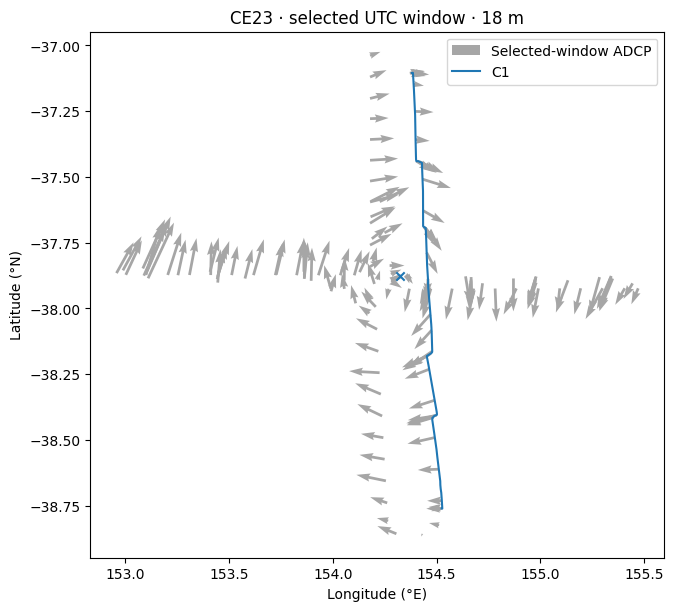

In [32]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, WINDOW_START, WINDOW_END, ORIGIN_LON_LAT,
    min_attendance=MIN_ATTENDANCE, instrument=ADCP_INSTRUMENT)
assert data.time.between(WINDOW_START, WINDOW_END).all()
display(pd.Series(audit, name="LATTE selection audit"))
display(pd.Series(backend_info, name="ESP backend"))
shown_depth = data.depth.min()
surface = data.loc[data.depth.eq(shown_depth)]
shown = surface.iloc[::max(1, len(surface)//150)]
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
ax.quiver(shown.lon, shown.lat, shown.u, shown.v, color="0.65", label="Selected-window ADCP")
for color, (ident, crossing) in zip(plt.cm.tab10(np.linspace(0, 1, len(transects))), transects.iterrows()):
    track = surface.loc[surface.time.between(pd.Timestamp(crossing.start), pd.Timestamp(crossing.end))]
    ax.plot(track.lon, track.lat, color=color, label=ident)
    fitted = solo.loc[solo.transect_id.eq(ident) & solo.inner_valid].sort_values("depth_m")
    if not fitted.empty:
        ax.scatter(fitted.iloc[0].xc_lon, fitted.iloc[0].yc_lat, marker="x", color=color)
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)", title=f"CE23 · selected UTC window · {shown_depth:g} m")
ax.set_aspect(1 / np.cos(np.deg2rad(surface.lat.mean())))
ax.legend()
plt.show()


## LATTE fits from shallow to deep

Every depth uses all usable samples from the configured time window. Accepted inner fits update the centre and ellipse, independently of Gaussian reconstruction acceptance. Radius tracking, when enabled, uses the last accepted Gaussian radius. All fit controls are in `CE23_latte.json`.


LATTE: 46/49 accepted inner fits; 46/49 accepted Gaussian reconstructions.
status
collinear_latte_sampling     1
invalid_ellipse              2
ok                          46
Centre offsets reference the shallowest accepted fit: 18 m.
Reconstructed measured levels: 18–378 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,18.0,ok,1258,660,True,True,0.9060,0.8809,1.2254,96488.2049,0.7980
1,26.0,ok,1247,638,True,True,0.8827,0.8959,1.2206,94737.4856,0.8098
2,34.0,ok,1264,621,True,True,0.8849,0.9119,1.1442,91096.7010,0.8141
3,42.0,ok,1250,595,True,True,0.8862,0.9186,1.1363,91695.7710,0.8207
4,50.0,ok,1250,598,True,True,0.8865,0.9186,1.1391,91869.5817,0.8240
5,58.0,ok,1264,613,True,True,0.8722,0.9181,1.1435,92555.8279,0.8279
6,65.9,ok,1263,619,True,True,0.8761,0.9168,1.1612,94518.9461,0.8317
7,73.9,ok,1261,627,True,True,0.8815,0.9187,1.1751,96592.5591,0.8358
8,81.9,ok,1266,664,True,True,0.9142,0.9110,1.2259,98945.5784,0.8365
9,89.9,ok,1273,673,True,True,0.8967,0.9114,1.2133,97790.4325,0.8372


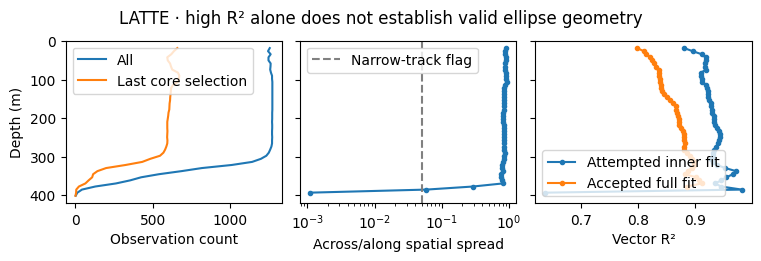

In [33]:
results, samples = esp.fit_depths(
    data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and reconstruction

Offsets are relative to LATTE's shallowest accepted centre; the chosen SOLO centre is only its initial seed. The horizontal maps, 3-D view and fixed zonal/meridional sections use the same helper and scales as the SOLO notebook. Reconstructed flow away from sampled points is model-based extrapolation, and the deepest ADCP bin does not define the eddy bottom.

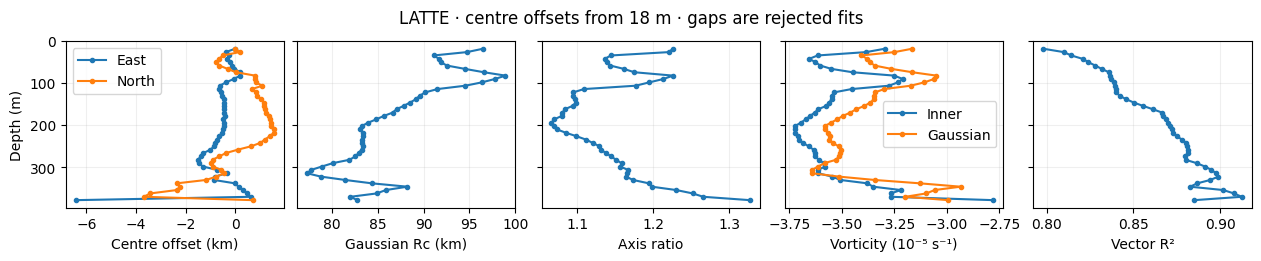

In [34]:
esp.plot_profiles(results)
plt.show()

1.34 km mean spacing


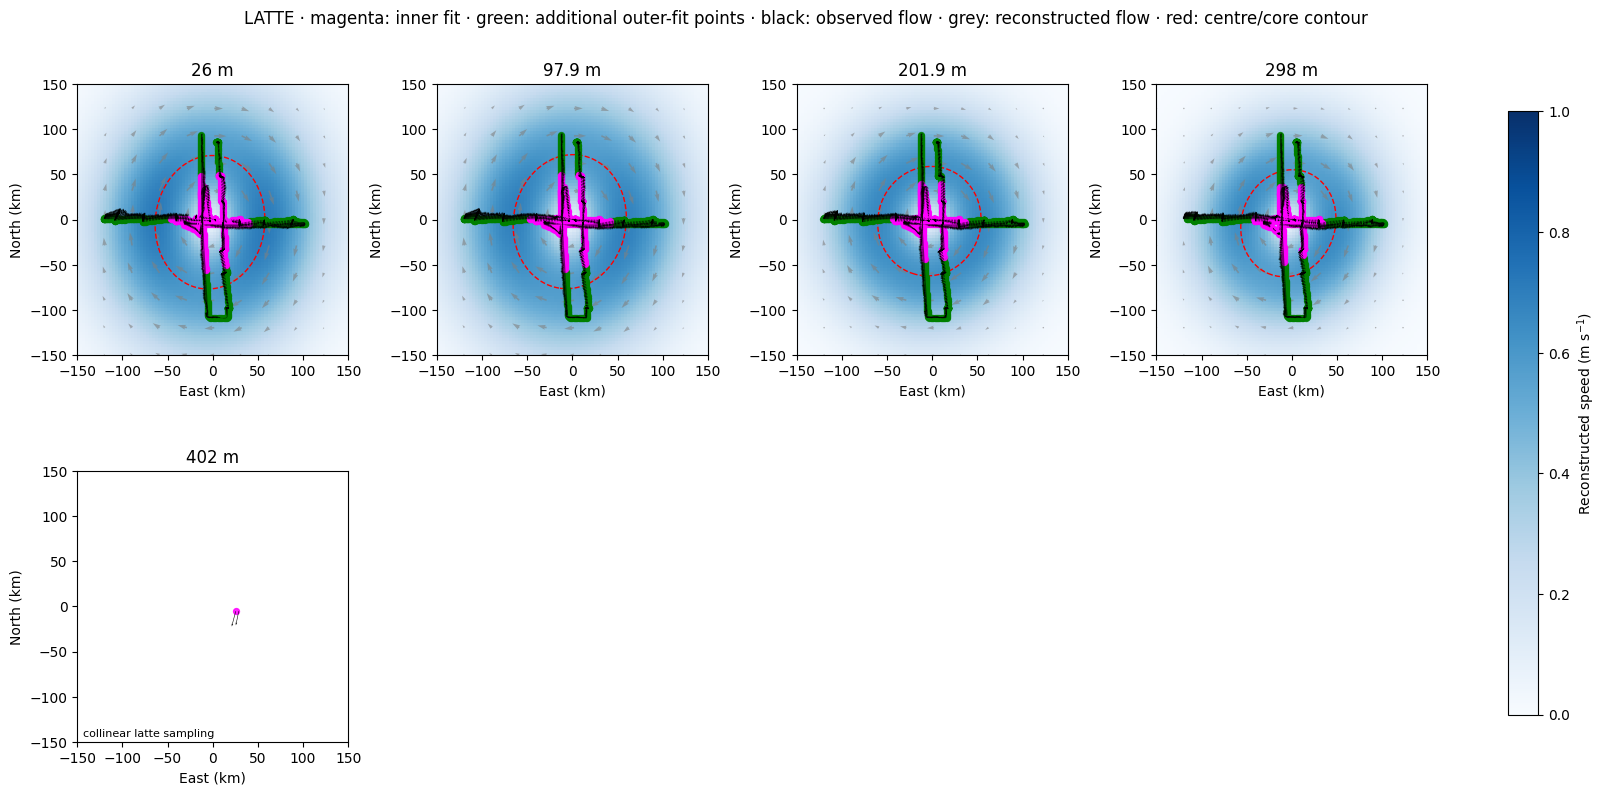

In [35]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

## Surface satellite velocity and LATTE samples

OceanCurrent daily geostrophic velocity is interpolated to the middle observed timestamp of the full selected LATTE survey. The shallowest measured ADCP bin, LATTE centre and accepted Gaussian maximum-speed ellipse are overlaid. Observations span several days, so the satellite snapshot does not represent the sampling time of every ADCP vector. Daily maps are downloaded and cached beside the CSV if missing. This optional plot requires satellite access and does not affect the fits or exports.


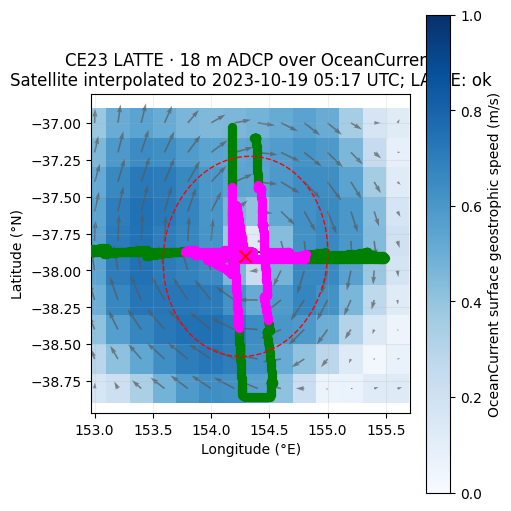

In [36]:
# fit_depths returns local metre coordinates; the satellite map uses lon/lat.
origin_lon, origin_lat = ORIGIN_LON_LAT
satellite_results = results.assign(
    xc_lon=origin_lon + results.xc_m / (111_000 * np.cos(np.deg2rad(origin_lat))),
    yc_lat=origin_lat + results.yc_m / 111_000)
fig, ax = esp.plot_solo_satellite_overlay(
    data, satellite_results, samples, DATA_PATH.parent, f"{EDDY} LATTE",
    half_width_km=120, speed_max=VELOCITY_LIMIT)
plt.show()


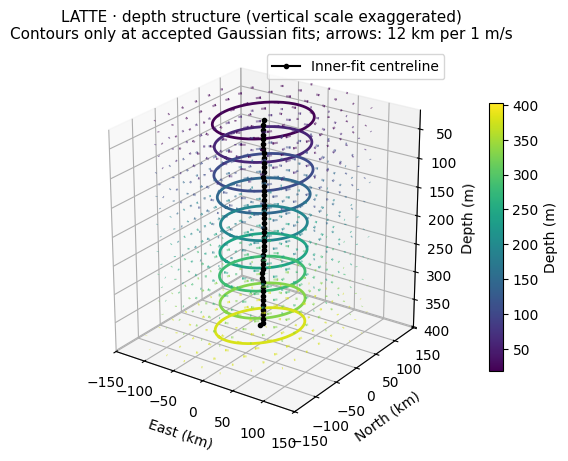

In [37]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()

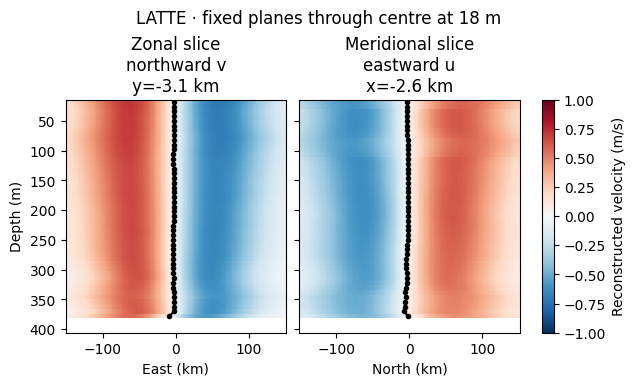

In [38]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

Export accepted and rejected measured depths, the requested UTC window, actual selection audit, SOLO seed, fit settings and backend fingerprint. Outputs stay beside the input CSV under `outputs/`.


In [39]:
SAVE_RESULTS = CONFIG["save_results"]
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / "ce23_latte_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, method="LATTE", data_path=str(DATA_PATH),
                      config_path=str(CONFIG_PATH), transects_config_path=str(TRANSECTS_PATH), backend=backend_info,
                      solo_results_path=str(SOLO_RESULTS_PATH),
                      solo_transect=SOLO_TRANSECT,
                      solo_surface_fit=SOLO_REF.to_dict(),
                      time_window_utc=CONFIG["time_window_utc"], selection=audit, fit_settings=FIT)
    (OUTPUT_DIR / "ce23_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE results to {OUTPUT_DIR}")

Saved LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2023_V06_adcp_trawler/outputs


## Along-track bin sensitivity

Set `along_track_bin_km` in `CE23_latte.json` to the widths to compare. The same binning and four-panel comparison as the SOLO notebooks are used, with LATTE fits and this notebook’s original fit settings. Each occupied projected along-track cell contributes one mean position and east/north velocity vector at each measured depth. All centre offsets reference the original shallowest accepted inner centre; `Rc` requires an accepted Gaussian fit and vorticity requires an accepted inner fit. This comparison does not change exported fits.

This uses the full selection within the configured UTC window, without a geographic filter. Bins project onto its shallowest-bin principal axis, so different ship passes at the same projected distance can be averaged together, including across sampling times. Interpret this as a regional sampling sensitivity rather than regular spacing along a single crossing.


,vectors,inner_depths,Rc_depths
bin,,,
Original,52281,46,46
2 km,4917,48,48
5 km,2022,46,46
10 km,1021,46,46
20 km,516,46,46


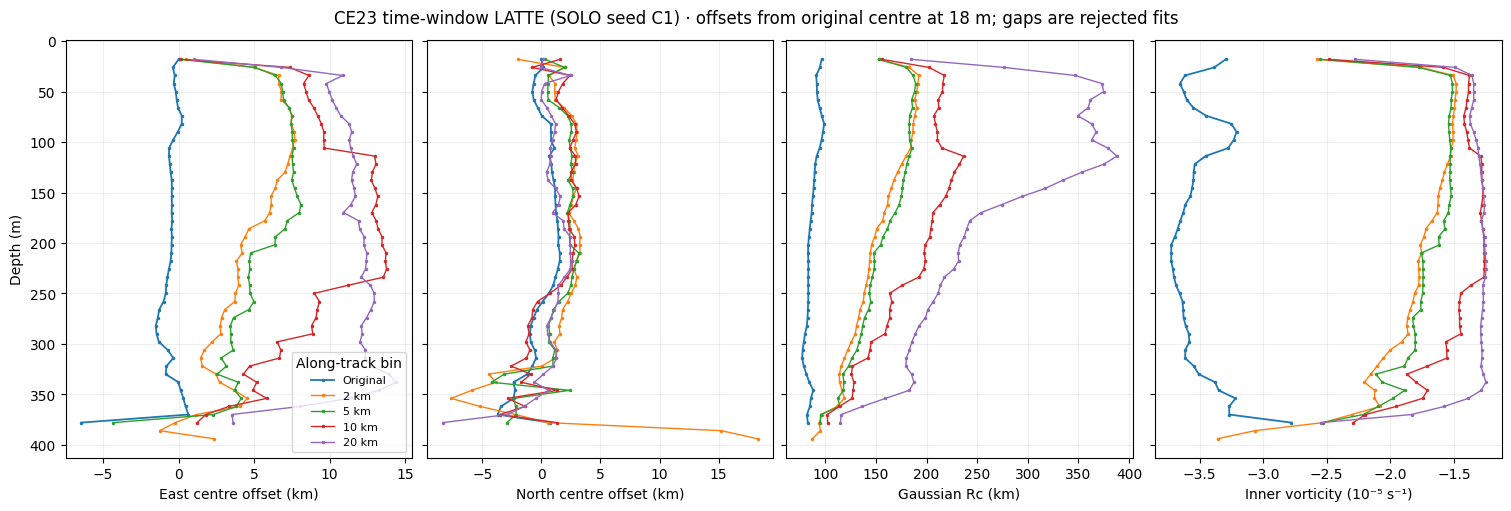

In [40]:
bin_data = data
bin_results = results
bin_coverage = coverage
bin_settings = FIT
bin_title = f"{EDDY} time-window LATTE (SOLO seed {SOLO_TRANSECT})"

BIN_WIDTHS_KM = json.loads(CONFIG_PATH.read_text())["along_track_bin_km"]
if len(BIN_WIDTHS_KM) != len(set(BIN_WIDTHS_KM)):
    raise ValueError("along_track_bin_km must contain unique widths")
bin_fits = {"Original": bin_results}
bin_counts = [{"bin": "Original", "vectors": len(bin_data),
               "inner_depths": int(bin_results.inner_valid.sum()), "Rc_depths": int(bin_results.valid.sum())}]
for width_km in BIN_WIDTHS_KM:
    binned = esp.bin_solo_along_track(bin_data, width_km)
    fitted, _ = esp.fit_depths(binned, backend, "LATTE",
                               depth_levels=bin_coverage.index, **bin_settings)
    label = f"{width_km:g} km"
    bin_fits[label] = fitted
    bin_counts.append({"bin": label, "vectors": len(binned),
                       "inner_depths": int(fitted.inner_valid.sum()),
                       "Rc_depths": int(fitted.valid.sum())})
display(pd.DataFrame(bin_counts).set_index("bin"))
esp.plot_solo_binning_comparison(bin_fits, bin_title)
plt.show()
